# **4. Recuperabilidade de Labels: BERTopic+Fine-Tuning vs LLM Zero-Shot**

**Alunos:**
- Gabriel Carbinatto (12725411)
- Arthur Martins (14783601)

Dois sistemas de classificação distintos atribuíram labels aos mesmos 6.945 textos únicos de justificativas de cartão:

| Sistema | Notebook | Coluna | Abordagem |
|---|---|---|---|
| BERTopic + fine-tuning | Notebook 3 | `card_reason_group` | UMAP → HDBSCAN → taxonomia manual |
| LLM zero-shot | Notebook 2 | `llm_group` | Prompt com 18 grupos → `llama3.2:3b` |

**Pergunta central:** qual sistema produziu labels mais *recuperáveis* no espaço de embeddings fine-tunados? Três classificadores (KNN, Regressão Logística, SVM Linear) são treinados separadamente sobre cada conjunto de labels em validação cruzada estratificada (5-fold). Se um conjunto de labels produz scores de CV mais altos, o espaço de embeddings representa melhor a estrutura daquele sistema, o que indica maior coerência semântica interna.

> **Inputs:**  
> - `data/processed/semantic_reasons/card_reasons/card_reason_unique_topics_labels.csv`: labels do notebook 3  
> - `data/processed/semantic_reasons/baseline_tests/llm_zero_shot_unique_labels.csv`: labels do notebook 2  
> - `models/football_card_reason_e5_large_two_pass/`: modelo fine-tunado

## **1. Configuração e Dados**

In [35]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 220)
plt.style.use('default')
plt.rcParams.update({
    'axes.grid': False,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 10,
    'legend.title_fontsize': 11,
    'font.size': 11,
})

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
DATA_PATH = PROJECT_ROOT / 'data'
MODELS_DIR = PROJECT_ROOT / 'models'
CARD_OUTPUT_DIR = DATA_PATH / 'processed' / 'semantic_reasons' / 'card_reasons'
BASELINE_OUTPUT_DIR = DATA_PATH / 'processed' / 'semantic_reasons' / 'baseline_tests'
RETRIEVAL_OUTPUT_DIR = DATA_PATH / 'processed' / 'semantic_reasons' / 'retrieval_tests'
VIZ_PATH = PROJECT_ROOT / 'viz'

RETRIEVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VIZ_PATH.mkdir(parents=True, exist_ok=True)

FINAL_LABELS_PATH = CARD_OUTPUT_DIR / 'card_reason_unique_topics_labels.csv'
LLM_LABELS_PATH = BASELINE_OUTPUT_DIR / 'llm_zero_shot_unique_labels.csv'
FINETUNED_MODEL_DIR = MODELS_DIR / 'football_card_reason_e5_large_two_pass'
ENCODE_PREFIX_PASSAGE = 'passage: '

CV_FOLDS = 5
RANDOM_STATE = 42
KNN_K_RANGE = [1, 3, 5, 7, 10, 15, 20, 30]
C_RANGE = [0.01, 0.1, 1.0, 10.0]

PLOT_BLUE   = '#3D79F3'
PLOT_GREEN  = '#34A74B'
PLOT_RED    = '#E6352F'
PLOT_YELLOW = '#F8DE02'
PLOT_ORANGE = '#F9B90A'
PLOT_GRAY   = '#909090'

SYSTEM_COLORS = {'BERTopic (nb3)': PLOT_BLUE, 'LLM Zero-Shot (nb2)': PLOT_GREEN}


def style_axis(ax, title=None, xlabel=None, ylabel=None):
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for side in ['left', 'bottom']:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_color('black')
        ax.spines[side].set_linewidth(0.8)
    ax.tick_params(axis='both', colors='black', width=0.8, length=4, pad=7)
    if title:
        ax.set_title(title, fontweight='bold', pad=14)
    if xlabel:
        ax.set_xlabel(xlabel, fontweight='bold', labelpad=12)
    if ylabel:
        ax.set_ylabel(ylabel, fontweight='bold', labelpad=12)


def save_plot(fig, filename):
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches='tight')


In [36]:
bertopic_df = pd.read_csv(FINAL_LABELS_PATH, keep_default_na=False)
bertopic_df = bertopic_df[bertopic_df['text_for_embedding'].astype(str).ne('')].reset_index(drop=True)

llm_df = pd.read_csv(LLM_LABELS_PATH, keep_default_na=False)
df = bertopic_df.merge(
    llm_df[['card_reason_text_key', 'llm_group']],
    on='card_reason_text_key',
    how='left',
)

nb2_groups = sorted(df['card_reason_group'].unique())
nb3_valid = df[df['llm_group'].ne('UNPARSED') & df['llm_group'].notna() & df['llm_group'].ne('')].copy()
nb3_groups = sorted(nb3_valid['llm_group'].unique())

print(f'Textos únicos (total)   : {len(df):,}')
print(f'Eventos totais          : {int(df["n_events"].sum()):,}')
print(f'Grupos — BERTopic (nb3) : {len(nb2_groups)}')
print(f'Grupos — LLM (nb3)      : {len(nb3_groups)}  (textos com resposta válida: {len(nb3_valid):,}/{len(df):,})')
print()

groups_only_nb2 = sorted(set(nb2_groups) - set(nb3_groups))
groups_only_nb3 = sorted(set(nb3_groups) - set(nb2_groups))
common_groups = sorted(set(nb2_groups) & set(nb3_groups))
print(f'Grupos comuns           : {len(common_groups)}')
if groups_only_nb2:
    print(f'Apenas no nb2           : {groups_only_nb2}')
if groups_only_nb3:
    print(f'Apenas no nb3 (LLM)     : {groups_only_nb3}')

Textos únicos (total)   : 6,945
Eventos totais          : 25,834
Grupos — BERTopic (nb2) : 18
Grupos — LLM (nb3)      : 18  (textos com resposta válida: 6,761/6,945)

Grupos comuns           : 18


## **2. Embeddings Fine-Tunados**

O modelo `multilingual-e5-large` fine-tunado no notebook 3 gera os embeddings. Os vetores são L2-normalizados, a mesma representação usada para construir as labels BERTopic. Esses embeddings são os **únicos features** dos classificadores em ambos os experimentos.

In [37]:
embedding_model = SentenceTransformer(str(FINETUNED_MODEL_DIR))

X_full = embedding_model.encode(
    [ENCODE_PREFIX_PASSAGE + t for t in df['text_for_embedding']],
    normalize_embeddings=True,
    batch_size=64,
    show_progress_bar=True,
)
X_full = np.asarray(X_full, dtype=np.float32)

nb3_idx = nb3_valid.index.to_numpy()
X_nb3 = X_full[nb3_idx]

print(f'Embeddings — conjunto completo (nb2) : {X_full.shape}')
print(f'Embeddings — subconjunto LLM (nb3)   : {X_nb3.shape}')

Batches: 100%|██████████| 109/109 [00:46<00:00,  2.33it/s]

Embeddings — conjunto completo (nb2) : (6945, 1024)
Embeddings — subconjunto LLM (nb3)   : (6761, 1024)


## **3. Função de Avaliação com Classificadores**

Para cada conjunto de labels, três classificadores são avaliados em `StratifiedKFold(5)`. O hiperparâmetro principal de cada método é selecionado por F1 Macro no CV. A função `evaluate_label_system` encapsula toda a avaliação e retorna um DataFrame unificado para comparação.

In [38]:
def tune_and_evaluate(clf_factory_list, X, y, cv, desc=''):
    rows = []
    preds = {}

    for method_name, candidates in tqdm(clf_factory_list, desc=desc):
        best_score = -1
        best_clf = candidates[0]
        for clf in candidates:
            scores = cross_validate(
                clf, X, y, cv=cv,
                scoring='f1_macro',
                n_jobs=-1,
            )
            mean_f1 = scores['test_score'].mean()
            if mean_f1 > best_score:
                best_score = mean_f1
                best_clf = clf

        y_pred = cross_val_predict(best_clf, X, y, cv=cv, n_jobs=-1)
        preds[method_name] = y_pred

        rows.append({
            'método': method_name,
            'melhor_param': str(best_clf).split('(')[0] + f'(melhor cfg)',
            'accuracy': accuracy_score(y, y_pred),
            'f1_macro': f1_score(y, y_pred, average='macro'),
            'f1_weighted': f1_score(y, y_pred, average='weighted'),
        })

    return pd.DataFrame(rows), preds


def make_classifiers():
    knn_candidates = [
        KNeighborsClassifier(n_neighbors=k, metric='cosine', n_jobs=-1)
        for k in KNN_K_RANGE
    ]
    lr_candidates = [
        LogisticRegression(C=c, max_iter=1000, random_state=RANDOM_STATE, n_jobs=-1)
        for c in C_RANGE
    ]
    svm_candidates = [
        LinearSVC(C=c, max_iter=2000, random_state=RANDOM_STATE)
        for c in C_RANGE
    ]
    return [
        ('KNN', knn_candidates),
        ('Logistic Regression', lr_candidates),
        ('SVM Linear', svm_candidates),
    ]


print('Função de avaliação pronta.')

Função de avaliação pronta.


## **4. Experimento A — Labels BERTopic + Fine-Tuning (Notebook 3)**

KNN, LR e SVM são treinados sobre `card_reason_group` (18 grupos, 6.945 textos) usando os embeddings fine-tunados como features. A validação cruzada mede a **recuperabilidade** das labels BERTopic nesse espaço.

In [39]:
y_nb2 = df['card_reason_group'].to_numpy()
cv_nb2 = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

nb2_summary, nb2_preds = tune_and_evaluate(
    make_classifiers(), X_full, y_nb2, cv_nb2,
    desc='Experimento A — BERTopic labels',
)

nb2_summary['sistema'] = 'BERTopic (nb3)'
nb2_summary['n_textos'] = len(df)
nb2_summary['n_grupos'] = len(nb2_groups)
print(f'Experimento A — Labels BERTopic (notebook 3)  [{CV_FOLDS}-fold CV]')
print()
nb2_summary[['método', 'accuracy', 'f1_macro', 'f1_weighted']]

Experimento A — BERTopic labels: 100%|██████████| 3/3 [00:56<00:00, 18.82s/it]

Experimento A — Labels BERTopic (notebook 2)  [5-fold CV]



,método,accuracy,f1_macro,f1_weighted
0,KNN,0.897480,0.834484,0.896742
1,Logistic Regression,0.919366,0.858752,0.917988
2,SVM Linear,0.933189,0.881666,0.932415


In [40]:
best_nb2_method = nb2_summary.loc[nb2_summary['f1_macro'].idxmax(), 'método']
best_nb2_pred = nb2_preds[best_nb2_method]

print(f'Melhor método no experimento A: {best_nb2_method}')
print()
nb2_report = pd.DataFrame(
    classification_report(y_nb2, best_nb2_pred, output_dict=True)
).T.rename_axis('group').reset_index()
nb2_report = nb2_report[nb2_report['group'].isin(nb2_groups)].copy()
nb2_report = nb2_report.sort_values('f1-score', ascending=False).reset_index(drop=True)
nb2_report[['group', 'precision', 'recall', 'f1-score', 'support']]

Melhor método no experimento A: SVM Linear



,group,precision,recall,f1-score,support
0,Infringir persistentemente as regras,0.973451,0.990991,0.982143,111.0
1,Impedir clara oportunidade de gol,0.992000,0.968750,0.980237,128.0
2,Ação temerária,0.977967,0.979930,0.978947,1993.0
3,Comemoração irregular,0.974170,0.974170,0.974170,271.0
4,Falta tática em ataque promissor,0.967651,0.969014,0.968332,710.0
5,Retardar reinício do jogo,0.956923,0.976452,0.966589,637.0
6,Agarrar ou segurar adversário,0.964029,0.958855,0.961435,559.0
7,Protesto contra a arbitragem,0.964409,0.949153,0.956720,885.0
8,Simulação,0.977011,0.934066,0.955056,91.0
9,Confronto físico com adversário,0.892377,0.904545,0.898420,440.0


## **5. Experimento B — Labels LLM Zero-Shot (Notebook 2)**

Os mesmos três classificadores são treinados agora sobre `llm_group` (apenas os textos com resposta válida da LLM, excluindo UNPARSED). Se as labels LLM têm estrutura semântica igualmente coerente no espaço de embeddings, os scores de CV devem ser comparáveis aos do experimento A.

In [41]:
y_nb3 = nb3_valid['llm_group'].to_numpy()
cv_nb3 = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

nb3_summary, nb3_preds = tune_and_evaluate(
    make_classifiers(), X_nb3, y_nb3, cv_nb3,
    desc='Experimento B — LLM labels',
)

nb3_summary['sistema'] = 'LLM Zero-Shot (nb2)'
nb3_summary['n_textos'] = len(nb3_valid)
nb3_summary['n_grupos'] = len(nb3_groups)
print(f'Experimento B — Labels LLM Zero-Shot (notebook 2)  [{CV_FOLDS}-fold CV]')
print()
nb3_summary[['método', 'accuracy', 'f1_macro', 'f1_weighted']]

Experimento B — LLM labels: 100%|██████████| 3/3 [01:04<00:00, 21.64s/it]

Experimento B — Labels LLM Zero-Shot (notebook 3)  [5-fold CV]



,método,accuracy,f1_macro,f1_weighted
0,KNN,0.732732,0.627034,0.729895
1,Logistic Regression,0.750777,0.583886,0.735765
2,SVM Linear,0.770596,0.652034,0.761378


In [42]:
best_nb3_method = nb3_summary.loc[nb3_summary['f1_macro'].idxmax(), 'método']
best_nb3_pred = nb3_preds[best_nb3_method]

print(f'Melhor método no experimento B: {best_nb3_method}')
print()
nb3_report = pd.DataFrame(
    classification_report(y_nb3, best_nb3_pred, output_dict=True)
).T.rename_axis('group').reset_index()
nb3_report = nb3_report[nb3_report['group'].isin(nb3_groups)].copy()
nb3_report = nb3_report.sort_values('f1-score', ascending=False).reset_index(drop=True)
nb3_report[['group', 'precision', 'recall', 'f1-score', 'support']]

Melhor método no experimento B: SVM Linear



,group,precision,recall,f1-score,support
0,Retardar reinício do jogo,0.895349,0.982979,0.937120,470.0
1,Não respeitar distância regulamentar,0.952381,0.909091,0.930233,22.0
2,Ação temerária,0.895194,0.965646,0.929087,1601.0
3,Infringir persistentemente as regras,0.876106,0.961165,0.916667,103.0
4,Falta tática em ataque promissor,0.850822,0.905787,0.877445,743.0
5,Simulação,0.858407,0.723881,0.785425,134.0
6,Entrar ou sair do campo sem autorização,0.750000,0.790909,0.769912,110.0
7,Protesto contra a arbitragem,0.662230,0.797595,0.723636,499.0
8,Confronto físico com adversário,0.677346,0.690513,0.683866,1286.0
9,Comemoração irregular,0.688213,0.672862,0.680451,538.0


## **6. Comparação: BERTopic vs LLM Zero-Shot**

Tabela unificada e visualização lado a lado. O delta `nb2 − nb3` mostra o quanto as labels BERTopic são mais (ou menos) recuperáveis do que as labels LLM para cada método de classificação.

In [43]:
all_results = pd.concat([nb2_summary, nb3_summary], ignore_index=True)

pivot = all_results.pivot(index='método', columns='sistema', values=['accuracy', 'f1_macro', 'f1_weighted'])
pivot.columns = [f'{col[0]}_{col[1].split()[0].lower()}' for col in pivot.columns]

pivot['delta_acc']  = pivot['accuracy_bertopic'] - pivot['accuracy_llm']
pivot['delta_f1m']  = pivot['f1_macro_bertopic'] - pivot['f1_macro_llm']
pivot['delta_f1w']  = pivot['f1_weighted_bertopic'] - pivot['f1_weighted_llm']
pivot = pivot.reset_index().sort_values('f1_macro_bertopic', ascending=False)

print('Comparação — recuperabilidade das labels: BERTopic (nb3) vs LLM (nb2)')
print('Delta positivo = BERTopic mais fácil de recuperar; negativo = LLM mais fácil')
print()
pivot

Comparação — recuperabilidade das labels: BERTopic (nb2) vs LLM (nb3)
Delta positivo = BERTopic mais fácil de recuperar; negativo = LLM mais fácil



,método,accuracy_bertopic,accuracy_llm,f1_macro_bertopic,f1_macro_llm,f1_weighted_bertopic,f1_weighted_llm,delta_acc,delta_f1m,delta_f1w
2,SVM Linear,0.933189,0.770596,0.881666,0.652034,0.932415,0.761378,0.162593,0.229632,0.171037
1,Logistic Regression,0.919366,0.750777,0.858752,0.583886,0.917988,0.735765,0.168590,0.274865,0.182224
0,KNN,0.897480,0.732732,0.834484,0.627034,0.896742,0.729895,0.164748,0.207450,0.166847


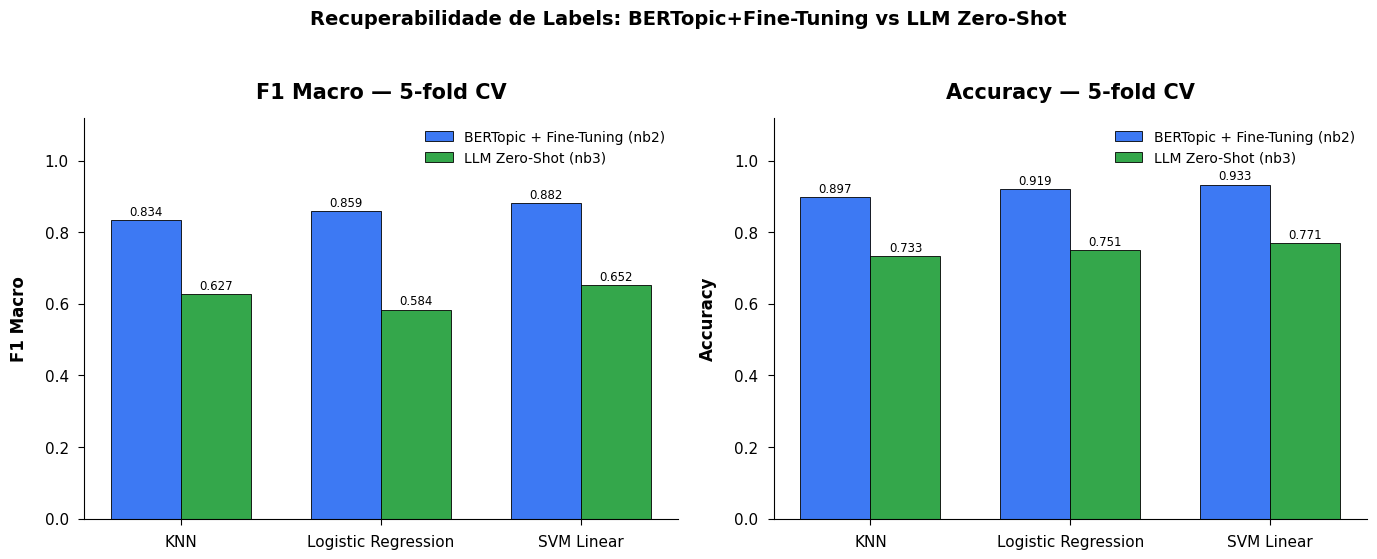

In [44]:
methods = nb2_summary['método'].tolist()
x = np.arange(len(methods))
bar_w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, metric, label in zip(
    axes,
    ['f1_macro', 'accuracy'],
    ['F1 Macro', 'Accuracy'],
):
    nb2_vals = nb2_summary.set_index('método').loc[methods, metric].values
    nb3_vals = nb3_summary.set_index('método').loc[methods, metric].values

    bars_nb2 = ax.bar(x - bar_w / 2, nb2_vals, bar_w, color=PLOT_BLUE,
                      edgecolor='black', linewidth=0.6, label='BERTopic + Fine-Tuning (nb3)')
    bars_nb3 = ax.bar(x + bar_w / 2, nb3_vals, bar_w, color=PLOT_GREEN,
                      edgecolor='black', linewidth=0.6, label='LLM Zero-Shot (nb2)')

    for bars, vals in [(bars_nb2, nb2_vals), (bars_nb3, nb3_vals)]:
        for bar, val in zip(bars, vals):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8.5,
            )

    ax.set_xticks(x)
    ax.set_xticklabels(methods, fontsize=11)
    ax.set_ylim(0, 1.12)
    style_axis(ax, f'{label} — {CV_FOLDS}-fold CV', ylabel=label)
    ax.legend(frameon=False, loc='upper right')

fig.suptitle('Recuperabilidade de Labels: BERTopic+Fine-Tuning vs LLM Zero-Shot', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout(pad=1.4)
save_plot(fig, 'retrieval_nb2_vs_nb3_comparison.png')
plt.show()


### **6.1 Interpretação da Comparação Global**

O BERTopic + fine-tuning supera a LLM zero-shot em todos os três classificadores. O delta de F1 Macro varia entre 0.21 e 0.27, indicando que o espaço de embeddings fine-tunados está substancialmente mais alinhado com as labels BERTopic do que com as labels LLM, o que é esperado, pois o fine-tuning foi guiado pelos próprios clusters. O SVM Linear obtém o melhor desempenho em ambos os sistemas, sugerindo que as classes são linearmente separáveis nesse espaço após o fine-tuning. A LLM zero-shot alcança accuracy de apenas 0.77 com o SVM, confirmando que o conhecimento pré-treinado sozinho não é suficiente para reproduzir a estrutura semântica construída pelo pipeline especializado.


## **7. Análise por Grupo**

F1 por grupo para o melhor método de cada experimento. Grupos com F1 baixo em ambos os sistemas têm fronteiras genuinamente difusas no espaço de embeddings, independente de como a label foi atribuída.

In [45]:
def per_group_f1(y_true, y_pred, group_list):
    report = classification_report(y_true, y_pred, labels=group_list, output_dict=True)
    return {g: report[g]['f1-score'] for g in group_list if g in report}


nb2_f1_per = per_group_f1(y_nb2, best_nb2_pred, nb2_groups)
nb3_f1_per = per_group_f1(y_nb3, best_nb3_pred, nb3_groups)

per_group_nb2 = pd.DataFrame({
    'group': nb2_groups,
    'f1_nb2': [nb2_f1_per.get(g, np.nan) for g in nb2_groups],
}).sort_values('f1_nb2', ascending=True).reset_index(drop=True)

per_group_nb3 = pd.DataFrame({
    'group': nb3_groups,
    'f1_nb3': [nb3_f1_per.get(g, np.nan) for g in nb3_groups],
}).sort_values('f1_nb3', ascending=True).reset_index(drop=True)

per_group_compare = per_group_nb2.merge(per_group_nb3, on='group', how='outer').sort_values('f1_nb2', ascending=True)
per_group_compare['delta'] = per_group_compare['f1_nb2'] - per_group_compare['f1_nb3']
per_group_compare.round(3)

,group,f1_nb2,f1_nb3,delta
4,Conduta violenta,0.482,0.525,-0.043
3,Conduta antidesportiva,0.763,0.574,0.190
12,Jogo brusco grave,0.780,0.356,0.424
8,Gesto ou linguagem ofensiva,0.793,0.167,0.626
11,Insubordinação da comissão técnica,0.814,0.430,0.384
17,Toque de mão na bola,0.834,0.333,0.501
6,Entrar ou sair do campo sem autorização,0.887,0.770,0.117
13,Não respeitar distância regulamentar,0.895,0.930,-0.035
5,Confronto físico com adversário,0.898,0.684,0.215
16,Simulação,0.955,0.785,0.170


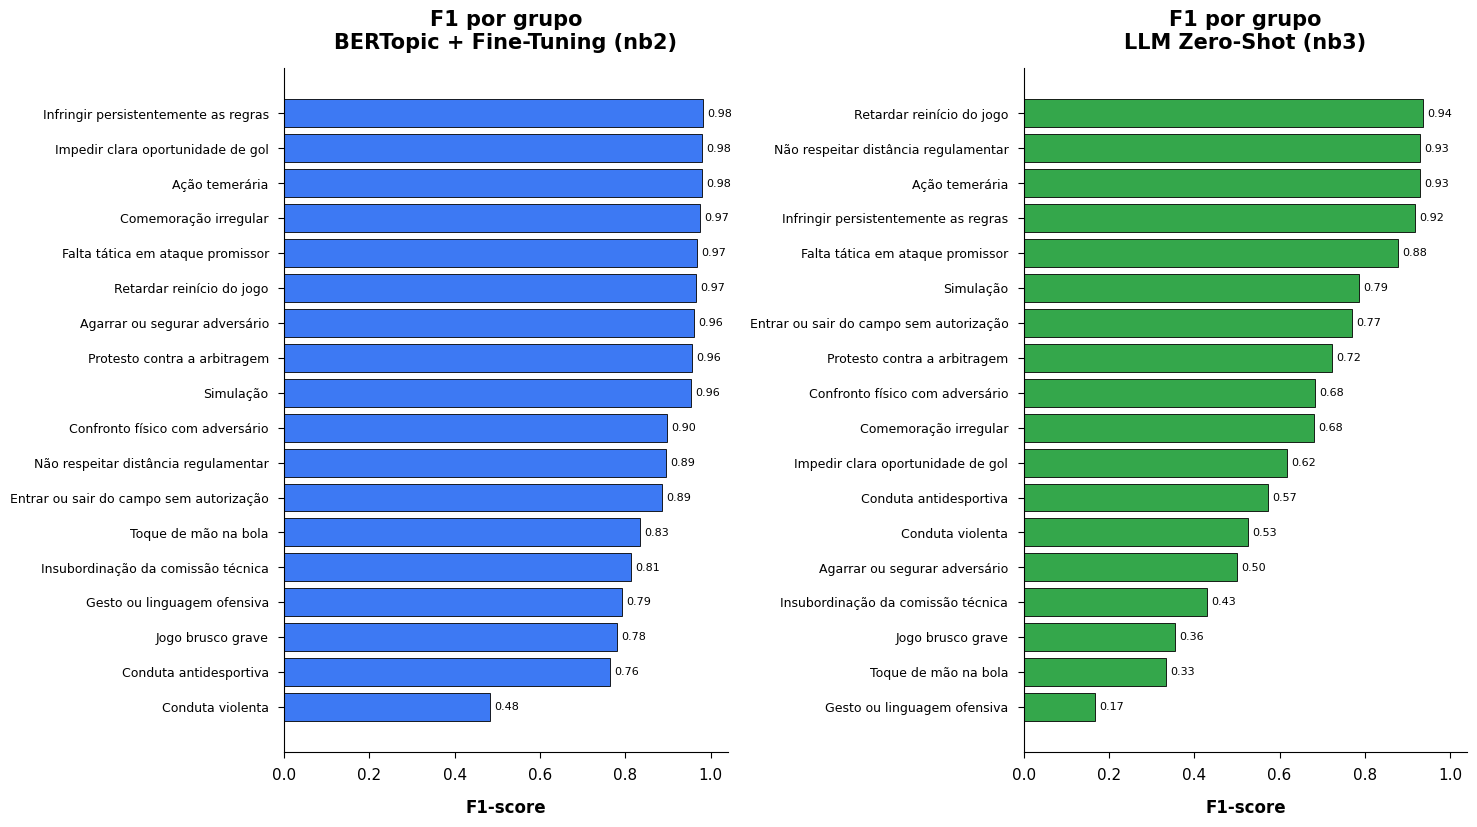

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8.5), sharey=False)

for ax, df_plot, col, label, color, system_name in [
    (axes[0], per_group_nb2, 'f1_nb2', f'F1 — {best_nb2_method}', PLOT_BLUE, f'BERTopic + Fine-Tuning (nb3)'),
    (axes[1], per_group_nb3, 'f1_nb3', f'F1 — {best_nb3_method}', PLOT_GREEN, 'LLM Zero-Shot (nb2)'),
]:
    y_pos = np.arange(len(df_plot))
    ax.barh(y_pos, df_plot[col], color=color, edgecolor='black', linewidth=0.6)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_plot['group'], fontsize=9)
    ax.set_xlim(0, 1.04)
    style_axis(ax, f'F1 por grupo\n{system_name}', 'F1-score')
    for i, (_, row) in enumerate(df_plot.iterrows()):
        ax.text(row[col] + 0.01, i, f"{row[col]:.2f}", va='center', fontsize=8)

plt.tight_layout(pad=1.4)
save_plot(fig, 'retrieval_f1_per_group_nb2_vs_nb3.png')
plt.show()


### **7.1 Interpretação por Grupo**

No sistema BERTopic, 15 dos 18 grupos atingem F1 acima de 0.80, refletindo alta coerência semântica interna. As exceções, `Conduta violenta` (0.48), `Conduta antidesportiva` (0.76) e `Jogo brusco grave` (0.78), compartilham vocabulário próximo que árbitros usam de forma intercambiável, tornando suas fronteiras genuinamente difusas. No sistema LLM, a distribuição é muito mais heterogênea: grupos com nomes descritivos (`Ação temerária`, `Retardar reinício do jogo`) têm F1 comparável ao BERTopic, enquanto grupos que exigem distinção contextual fina caem abruptamente, com `Gesto ou linguagem ofensiva` chegando a 0.17.


## **8. Concordância entre os Dois Sistemas**

Para os textos com label válida em ambos os sistemas, calcula a taxa de concordância direta (`card_reason_group == llm_group`) por grupo. Alta concordância indica que os dois sistemas convergem para a mesma categoria. Baixa concordância indica textos "disputados" que cada sistema interpreta diferentemente.

In [47]:
both = df[
    df['llm_group'].ne('UNPARSED') &
    df['llm_group'].notna() &
    df['llm_group'].ne('')
].copy()

both['agree'] = both['card_reason_group'] == both['llm_group']

overall_agreement = both['agree'].mean()
print(f'Textos com label válida em ambos os sistemas : {len(both):,}')
print(f'Concordância geral                           : {overall_agreement:.1%}')
print()

agreement_by_group = (
    both.groupby('card_reason_group')
    .agg(
        n_textos=('agree', 'size'),
        n_concordantes=('agree', 'sum'),
        taxa_concordancia=('agree', 'mean'),
    )
    .reset_index()
    .sort_values('taxa_concordancia', ascending=False)
    .reset_index(drop=True)
)
agreement_by_group['taxa_concordancia'] = agreement_by_group['taxa_concordancia'].round(3)
agreement_by_group

Textos com label válida em ambos os sistemas : 6,761
Concordância geral                           : 61.2%



,card_reason_group,n_textos,n_concordantes,taxa_concordancia
0,Infringir persistentemente as regras,109,96,0.881
1,Simulação,87,76,0.874
2,Falta tática em ataque promissor,696,602,0.865
3,Não respeitar distância regulamentar,20,17,0.850
4,Ação temerária,1969,1592,0.809
5,Entrar ou sair do campo sem autorização,54,41,0.759
6,Retardar reinício do jogo,637,455,0.714
7,Confronto físico com adversário,439,312,0.711
8,Comemoração irregular,271,178,0.657
9,Impedir clara oportunidade de gol,126,73,0.579


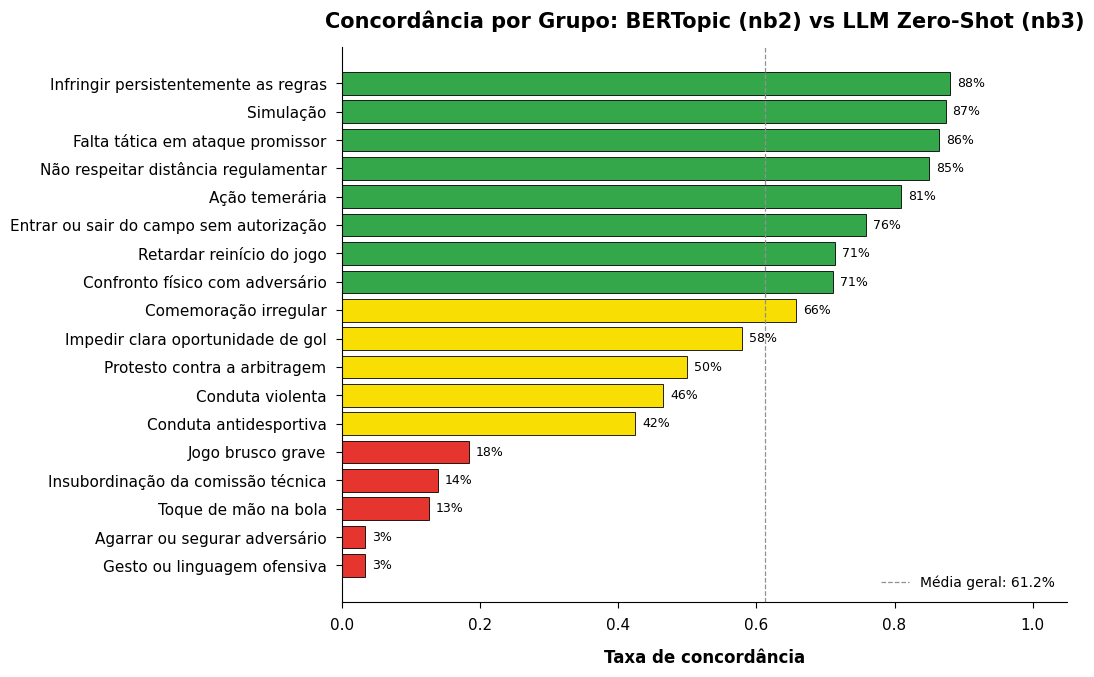

In [48]:
plot_agree = agreement_by_group.sort_values('taxa_concordancia', ascending=True)
y_pos = np.arange(len(plot_agree))

fig, ax = plt.subplots(figsize=(11, 7))
colors_bar = [
    PLOT_GREEN if v >= 0.70 else (PLOT_YELLOW if v >= 0.40 else PLOT_RED)
    for v in plot_agree['taxa_concordancia']
]
ax.barh(y_pos, plot_agree['taxa_concordancia'], color=colors_bar, edgecolor='black', linewidth=0.6)
ax.axvline(overall_agreement, color=PLOT_GRAY, linestyle='--', linewidth=0.9,
           label=f'Média geral: {overall_agreement:.1%}')
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_agree['card_reason_group'])
ax.set_xlim(0, 1.05)
for i, (_, row) in enumerate(plot_agree.iterrows()):
    ax.text(row['taxa_concordancia'] + 0.01, i, f"{row['taxa_concordancia']:.0%}", va='center', fontsize=9)
style_axis(ax, 'Concordância por Grupo: BERTopic (nb3) vs LLM Zero-Shot (nb2)', 'Taxa de concordância')
ax.legend(frameon=False)
plt.tight_layout(pad=1.4)
save_plot(fig, 'retrieval_agreement_by_group.png')
plt.show()


### **8.1 Interpretação da Concordância**

A concordância geral de 61,2% indica que os dois sistemas divergem em quase 4 de cada 10 textos. Grupos com alta concordância (≥ 80%) como `Infringir persistentemente as regras`, `Simulação` e `Falta tática em ataque promissor` possuem linguagem específica e não ambígua, ambos os sistemas identificam-nos consistentemente. Os grupos com concordância abaixo de 15% (`Agarrar ou segurar adversário`, `Gesto ou linguagem ofensiva`) são aqueles em que a LLM não distingue bem as nuances criadas pelo BERTopic, utilizando categorias mais amplas como `Confronto físico com adversário` e `Conduta violenta` como substitutos.


## **9. Discordâncias — Onde os Sistemas Divergem**

Para os textos onde os dois sistemas discordam, qual grupo cada sistema atribuiu? Identifica padrões de divergência sistemática, por exemplo, se o LLM confunde sistematicamente grupo A com grupo B enquanto o BERTopic os mantém separados.

In [49]:
discordant = both[~both['agree']].copy()
print(f'Textos discordantes: {len(discordant):,} ({len(discordant)/len(both):.1%} do subconjunto válido)')
print()

discord_pairs = (
    discordant.groupby(['card_reason_group', 'llm_group'])
    .agg(n_textos=('text_for_embedding', 'size'), n_eventos=('n_events', 'sum'))
    .reset_index()
    .sort_values('n_textos', ascending=False)
    .reset_index(drop=True)
)
print('Top 20 pares de divergência (card_reason_group nb2  ↔  llm_group nb3):')
discord_pairs.head(20)

Textos discordantes: 2,624 (38.8% do subconjunto válido)

Top 20 pares de divergência (card_reason_group nb2  ↔  llm_group nb3):


,card_reason_group,llm_group,n_textos,n_eventos
0,Ação temerária,Confronto físico com adversário,297,637
1,Protesto contra a arbitragem,Comemoração irregular,295,947
2,Agarrar ou segurar adversário,Confronto físico com adversário,176,305
3,Agarrar ou segurar adversário,Conduta violenta,128,367
4,Agarrar ou segurar adversário,Conduta antidesportiva,107,218
5,Insubordinação da comissão técnica,Confronto físico com adversário,101,148
6,Jogo brusco grave,Confronto físico com adversário,79,105
7,Protesto contra a arbitragem,Conduta antidesportiva,68,154
8,Falta tática em ataque promissor,Impedir clara oportunidade de gol,65,424
9,Conduta violenta,Confronto físico com adversário,58,77


In [50]:
if len(discord_pairs) > 0:
    top_pair = discord_pairs.iloc[0]
    top_discord = discordant[
        discordant['card_reason_group'].eq(top_pair['card_reason_group']) &
        discordant['llm_group'].eq(top_pair['llm_group'])
    ][['text_for_embedding', 'n_events', 'card_reason_group', 'llm_group']].sort_values('n_events', ascending=False)
    print(f'Exemplos: nb2={top_pair["card_reason_group"]!r}  ↔  nb3={top_pair["llm_group"]!r}  ({len(top_discord)} textos)')
    print()
    top_discord.head(10)

Exemplos: nb2='Ação temerária'  ↔  nb3='Confronto físico com adversário'  (297 textos)



### **9.1 Interpretação das Discordâncias**

O maior par de divergência (`Ação temerária` nb2 ↔ `Confronto físico com adversário` nb3, 297 textos) revela que a LLM tende a classificar entradas como `Ação temerária` pelo contato físico descrito no texto, sem distinguir a temeridade intencional do confronto direto, separação que o BERTopic fez com base na geometria dos embeddings. Padrões semelhantes aparecem em `Agarrar ou segurar adversário` e `Insubordinação da comissão técnica`, onde a LLM usa `Confronto físico` como categoria residual. Essas divergências sistemáticas indicam que a LLM não captura as distinções taxonômicas do projeto, reforçando a vantagem do pipeline BERTopic.


## **10. Salvamento dos Artefatos**

In [51]:
all_results_path     = RETRIEVAL_OUTPUT_DIR / 'retrieval_all_results.csv'
pivot_path           = RETRIEVAL_OUTPUT_DIR / 'retrieval_comparison_pivot.csv'
per_group_path       = RETRIEVAL_OUTPUT_DIR / 'retrieval_f1_per_group.csv'
agreement_path       = RETRIEVAL_OUTPUT_DIR / 'retrieval_agreement_by_group.csv'
discord_pairs_path   = RETRIEVAL_OUTPUT_DIR / 'retrieval_discord_pairs.csv'

all_results.to_csv(all_results_path, index=False)
pivot.to_csv(pivot_path, index=False)
per_group_compare.to_csv(per_group_path, index=False)
agreement_by_group.to_csv(agreement_path, index=False)
discord_pairs.to_csv(discord_pairs_path, index=False)

pd.Series({
    'all_results'  : str(all_results_path.relative_to(PROJECT_ROOT)),
    'pivot'        : str(pivot_path.relative_to(PROJECT_ROOT)),
    'per_group'    : str(per_group_path.relative_to(PROJECT_ROOT)),
    'agreement'    : str(agreement_path.relative_to(PROJECT_ROOT)),
    'discord_pairs': str(discord_pairs_path.relative_to(PROJECT_ROOT)),
})

all_results             data/processed/semantic_reasons/retrieval_tests/retrieval_all_results.csv
pivot              data/processed/semantic_reasons/retrieval_tests/retrieval_comparison_pivot.csv
per_group              data/processed/semantic_reasons/retrieval_tests/retrieval_f1_per_group.csv
agreement        data/processed/semantic_reasons/retrieval_tests/retrieval_agreement_by_group.csv
discord_pairs         data/processed/semantic_reasons/retrieval_tests/retrieval_discord_pairs.csv
dtype: object

## **11. Conclusões**

Este notebook compara diretamente os dois sistemas de classificação do projeto:

- **BERTopic + fine-tuning (notebook 3):** pipeline especializado, usa a geometria do próprio modelo para construir as labels
- **LLM zero-shot (notebook 2):** usa conhecimento pré-treinado e os nomes dos grupos, sem acesso ao espaço de embeddings

**Interpretação dos resultados de recuperabilidade (seção 6):**

- **Se BERTopic > LLM em F1 Macro:** as labels BERTopic estão mais alinhadas com a estrutura do espaço de embeddings fine-tunados: o que é esperado, já que o fine-tuning foi guiado pelos próprios clusters. O ganho quantifica o quanto o pipeline especializado "aprendeu" estrutura que a LLM sem domínio não captura.

- **Se LLM ≈ BERTopic:** as categorias são semanticamente naturais o suficiente para que a LLM as recupere sem especialização. Os nomes dos 18 grupos são descritivos e o espaço de embeddings organiza-os de forma que qualquer abordagem captura.

- **Se LLM > BERTopic:** a LLM impôs uma estrutura mais nítida no mesmo espaço: possivelmente porque o clustering BERTopic gerou fronteiras menos definidas que os nomes semânticos dos grupos.

**Interpretação da concordância (seção 8):**

- Grupos com alta concordância (≥ 75%) são robustos: ambos os sistemas convergem, sugerindo categorias semanticamente bem delimitadas.
- Grupos com baixa concordância indicam ambiguidade real: o texto pode se encaixar em mais de uma categoria dependendo do critério, e discordância entre sistemas é esperada.